Loading data...
Data loaded with columns: ['longitude', 'latitude', 'altitude_last_valid', 'sp', 'ssrd', 'str', 'strd', 't2m', 'u10', 'v10', 'snowc', 'sde', 'asn', 'year', 'month', 'albedo', 'station']
Filtering out single-year stations...
Data after filtering: 4448 records.
Filtering data between 1990 and 2020...
Data after year filtering: 4210 records.
Quick SHAP check with small model...
Quick SHAP check passed. SHAP shape: (4210, 15), X shape: (4210, 15)

=== Fold 1 ===
Best params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Fold 1 - RMSE: 0.0776, R²: 0.8235

=== Fold 2 ===
Best params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Fold 2 - RMSE: 0.0747, R²: 0.8366

=== Fold 3 ===
Best params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Fold 3 - RMSE: 0.0786, R²: 0.8123

=== Fold 4 ===
Best params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Fold 4 - RMSE: 0.0741, R²: 0.8281

=== Fold 5 ===
Best params: {'ma

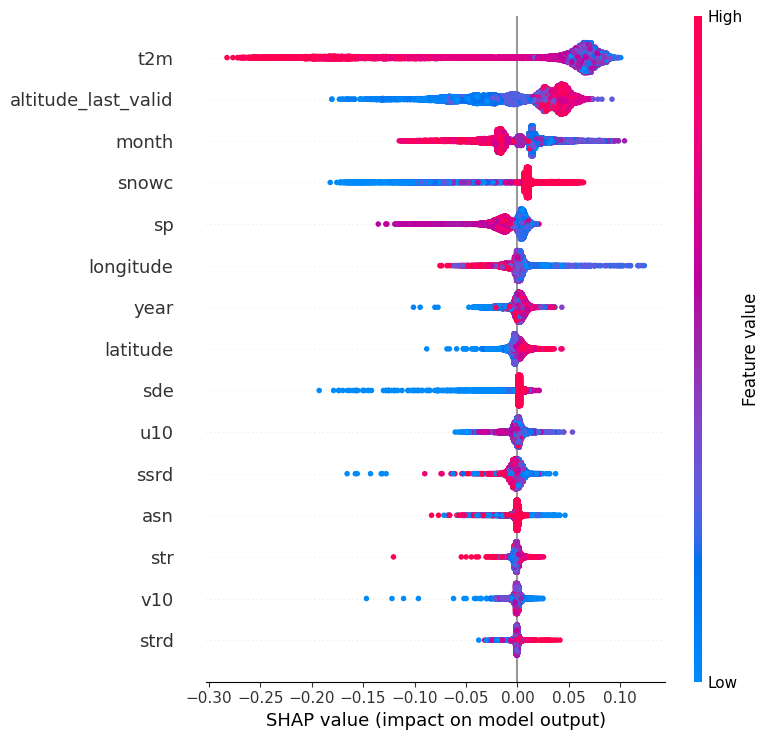

Done.


In [15]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm

# Step 1: 加载数据
file_path = "F:/TUB/greenlandProject/ERA5LAND/merged_allfeature.csv"
print("Loading data...")

try:
    df = pd.read_csv(file_path, delimiter=',')
    df.columns = df.columns.str.strip()
    print(f"Data loaded with columns: {df.columns.tolist()}")
except Exception as e:
    print(f"Error loading data: {e}")

# Step 2: 删除不需要的站点
print("Filtering out single-year stations...")
try:
    df_filtered = df[~df['station'].isin(['KAN_T', 'RED_L'])]
    print(f"Data after filtering: {df_filtered.shape[0]} records.")
except Exception as e:
    print(f"Error filtering stations: {e}")

# Step 3: 保留1990–2020年的数据
print("Filtering data between 1990 and 2020...")
try:
    df_filtered = df_filtered[(df_filtered['year'] >= 1990) & (df_filtered['year'] <= 2023)]
    print(f"Data after year filtering: {df_filtered.shape[0]} records.")
except Exception as e:
    print(f"Error filtering years: {e}")

# Step 4: 特征和标签
input_features = ['longitude', 'latitude', 'altitude_last_valid', 'sp', 'ssrd', 'str', 
                  'strd', 't2m', 'u10', 'v10', 'snowc', 'sde', 'asn', 'year', 'month']
output_feature = 'albedo'

X = df_filtered[input_features]
y = df_filtered[output_feature]

# Step 5: 先快速训练一个小模型测试SHAP（确保后续流程正常）
print("Quick SHAP check with small model...")
try:
    small_rf = RandomForestRegressor(n_estimators=10, max_depth=5, random_state=42)
    small_rf.fit(X, y)
    explainer = shap.TreeExplainer(small_rf)
    shap_values_check = explainer.shap_values(X)
    print(f"Quick SHAP check passed. SHAP shape: {shap_values_check.shape}, X shape: {X.shape}")
except Exception as e:
    print(f"Error during quick SHAP check: {e}")
    raise ValueError("SHAP check failed, stop training!")

# Step 6: 开始正式5折交叉验证
kf = KFold(n_splits=5, shuffle=True, random_state=42)
shap_values_all = []
X_train_all = []

# 设置随机森林参数网格（小网格快速版）
param_grid = {
    'n_estimators': [100],
    'max_depth': [10, 20],
    'min_samples_split': [2],
}

fold_counter = 1
for train_idx, val_idx in kf.split(X):
    print(f"\n=== Fold {fold_counter} ===")
    
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # 超参数搜索
    rf_model = RandomForestRegressor(random_state=42)
    grid_search = GridSearchCV(rf_model, param_grid, cv=3, scoring='neg_mean_squared_error', verbose=0)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
    print(f"Best params: {grid_search.best_params_}")

    # 验证集性能
    y_pred = best_model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)
    print(f"Fold {fold_counter} - RMSE: {rmse:.4f}, R²: {r2:.4f}")

    # 只对训练集计算SHAP值
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_train)

    # 保存每折的SHAP和对应X
    shap_values_all.append(shap_values)
    X_train_all.append(X_train)

    fold_counter += 1

# Step 7: 合并所有折的SHAP值和X
print("\nCombining SHAP values across all folds...")
shap_values_combined = np.vstack(shap_values_all)
X_combined = pd.concat(X_train_all, axis=0)

print(f"Combined SHAP values shape: {shap_values_combined.shape}")
print(f"Combined X shape: {X_combined.shape}")

# Step 8: 画最终的SHAP特征重要性图
print("Plotting SHAP summary plot...")
shap.summary_plot(shap_values_combined, X_combined)
print("Done.")
